# Graph — Klasifikasi Simpul (tanpa deep learning)
**Kapan dipakai:** tiap simpul (makalah, akun, pengguna) punya feature sendiri dan terhubung
dengan simpul lain; tebak label simpul yang belum diketahui.

**Idenya:** feature asli simpul ditambah feature struktur graf (derajat, PageRank, clustering,
core number, embedding spektral), lalu model tabular biasa.

**Langkah:**
1. Bangun graf, hitung feature struktur tiap simpul.
2. Split simpul, latih model, evaluasi.
3. Simpan prediksi simpul uji.

**Data demo:** Cora (7 topik makalah, feature kata `w0..w1432`). Versi GNN: notebook `gcn`.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import SpectralEmbedding
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/graph/cora"   # GANTI saat lomba
NODES_CSV = f"{DATA_FOLDER}/nodes.csv"
EDGES_CSV = f"{DATA_FOLDER}/edges.csv"

NODE_ID_COL = "id"
SOURCE_COL = "source"
TARGET_COL = "target"
LABEL_COL = "label"
DROP_COLS = ["id", "label"]     # kolom yang bukan feature
SPECTRAL_DIM = 16               # jumlah dimensi embedding spektral
SEED = 42

## Baca data

In [3]:
nodes = pd.read_csv(NODES_CSV)
edges = pd.read_csv(EDGES_CSV)
missing = nodes.isna().sum()
print(nodes.shape, edges.shape, "| missing:", missing.sum())
nodes[DROP_COLS].head()

(2708, 1435) (5429, 2) | missing: 0


,id,label
0,0,Neural_Networks
1,1,Rule_Learning
2,2,Reinforcement_Learning
3,3,Reinforcement_Learning
4,4,Probabilistic_Methods


## EDA: jumlah simpul per label

label
Neural_Networks           818
Probabilistic_Methods     426
Genetic_Algorithms        418
Theory                    351
Case_Based                298
Reinforcement_Learning    217
Rule_Learning             180
Name: count, dtype: int64


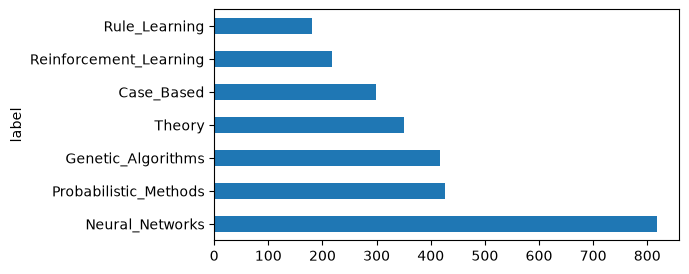

In [4]:
label_counts = nodes[LABEL_COL].value_counts()
print(label_counts)
label_counts.plot.barh(figsize=(6, 3))
plt.show()

## Bangun graf
`adjacency` = matriks simpul x simpul, 1 bila ada sisi (urutan baris = urutan `nodes`).

In [5]:
graph = nx.Graph()
graph.add_nodes_from(nodes[NODE_ID_COL])
graph.add_edges_from(zip(edges[SOURCE_COL], edges[TARGET_COL]))
graph.remove_edges_from(nx.selfloop_edges(graph))     # buang sisi dari simpul ke dirinya sendiri
node_order = list(nodes[NODE_ID_COL])
adjacency = nx.to_scipy_sparse_array(graph, nodelist=node_order, format="csr")
print(graph.number_of_nodes(), "simpul,", graph.number_of_edges(), "sisi")

2708 simpul, 5278 sisi


## Langkah 1 — feature struktur graf
- **degree** jumlah tetangga, **pagerank** pengaruh, **clustering** tetangga saling kenal,
  **core** seberapa dalam di inti graf.
- **Embedding spektral:** posisi simpul di "peta" graf (simpul yang berdekatan = mirip).

In [6]:
structure = pd.DataFrame()
structure["degree"] = nodes[NODE_ID_COL].map(dict(graph.degree()))
structure["pagerank"] = nodes[NODE_ID_COL].map(nx.pagerank(graph))
structure["clustering"] = nodes[NODE_ID_COL].map(nx.clustering(graph))
structure["core"] = nodes[NODE_ID_COL].map(nx.core_number(graph))

spectral = SpectralEmbedding(n_components=SPECTRAL_DIM, affinity="precomputed",
                             random_state=SEED)
spectral_values = spectral.fit_transform(adjacency.toarray())
for dim in range(SPECTRAL_DIM):
    structure[f"spectral{dim}"] = spectral_values[:, dim]

word_features = nodes.drop(columns=DROP_COLS)
all_features = pd.concat([word_features, structure], axis=1)
print("jumlah feature:", all_features.shape[1])
structure.head()

Z:\GEMASTIK-DATABASE\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


jumlah feature: 1453


,degree,pagerank,clustering,core,spectral0,spectral1,spectral2,spectral3,spectral4,spectral5,spectral6,spectral7,spectral8,spectral9,spectral10,spectral11,spectral12,spectral13,spectral14,spectral15
0,5,0.000384,0.800000,4,1.003772e-07,-6.037768e-09,-4.853361e-08,-3.080397e-07,7.294823e-08,1.178425e-07,-2.467770e-07,-4.623714e-07,0.000008,0.009932,0.00001,-0.000002,-4.484768e-07,-3.765527e-08,-1.049154e-09,-2.300605e-08
1,1,0.000122,0.000000,1,1.003772e-07,-6.037768e-09,-4.853361e-08,-3.080397e-07,7.294823e-08,1.178425e-07,-2.467770e-07,-4.623714e-07,0.000008,0.009932,0.00001,-0.000002,-4.484768e-07,-3.765527e-08,-1.049154e-09,-2.300605e-08
2,4,0.000291,0.166667,4,1.003772e-07,-6.037768e-09,-4.853361e-08,-3.080397e-07,7.294823e-08,1.178425e-07,-2.467770e-07,-4.623714e-07,0.000008,0.009932,0.00001,-0.000002,-4.484768e-07,-3.765527e-08,-1.049154e-09,-2.300605e-08
3,3,0.000245,0.000000,3,1.003772e-07,-6.037768e-09,-4.853361e-08,-3.080397e-07,7.294823e-08,1.178425e-07,-2.467770e-07,-4.623714e-07,0.000008,0.009932,0.00001,-0.000002,-4.484768e-07,-3.765527e-08,-1.049154e-09,-2.300605e-08
4,1,0.000169,0.000000,1,1.003772e-07,-6.037768e-09,-4.853361e-08,-3.080397e-07,7.294823e-08,1.178425e-07,-2.467770e-07,-4.623714e-07,0.000008,0.009932,0.00001,-0.000002,-4.484768e-07,-3.765527e-08,-1.049154e-09,-2.300605e-08


## Split simpul
Untuk melihat nilai tambah struktur graf, ganti `X = all_features` dengan `X = word_features`.

In [7]:
X = all_features
# X = word_features                 # hanya feature kata, tanpa struktur graf
y = nodes[LABEL_COL]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, stratify=y,
                                                  random_state=SEED)

## Langkah 2 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [8]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
# model = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=500,
#                                                                random_state=SEED))
# model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
#                        random_state=SEED, verbose=-1)
# model = make_pipeline(StandardScaler(), SVC(C=10, random_state=SEED))
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED)
# model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128,),
#                                                       max_iter=1000, random_state=SEED))

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['Case_Based','Genetic_Algorithms','Neural_Networks',..., 'Reinforcement_Learning','Rule_Learning','Theory']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1453,)","['w0','w1','w2',...,'spectral13','spectral14','spectral15']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1453
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Evaluasi

F1 macro: 0.7211183007322226
Akurasi: 0.7355473554735548
                        precision    recall  f1-score   support

            Case_Based       0.77      0.72      0.74        89
    Genetic_Algorithms       0.80      0.83      0.82       126
       Neural_Networks       0.73      0.77      0.75       246
 Probabilistic_Methods       0.75      0.71      0.73       128
Reinforcement_Learning       0.72      0.82      0.76        65
         Rule_Learning       0.69      0.54      0.60        54
                Theory       0.65      0.63      0.64       105

              accuracy                           0.74       813
             macro avg       0.73      0.72      0.72       813
          weighted avg       0.73      0.74      0.73       813



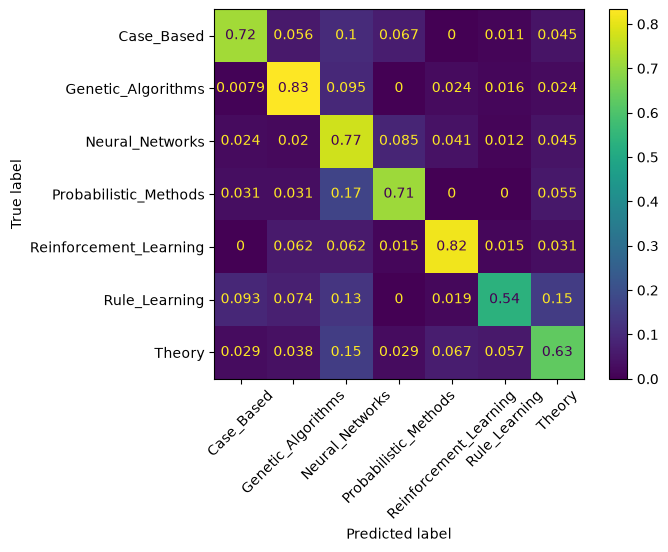

In [9]:
pred_val = model.predict(X_val)
print("F1 macro:", f1_score(y_val, pred_val, average="macro"))
print("Akurasi:", accuracy_score(y_val, pred_val))
print(classification_report(y_val, pred_val))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, xticks_rotation=45, normalize="true")
plt.show()

## Langkah 3 — simpan prediksi simpul uji
Cora tidak punya file test, jadi yang disimpan adalah prediksi untuk simpul validasi.
Saat lomba: simpul tanpa label = test. Latih di semua simpul berlabel, prediksi simpul test.

In [10]:
predictions = model.predict(X_val)

submission = pd.DataFrame()
submission["id"] = nodes[NODE_ID_COL][X_val.index]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
808,808,Neural_Networks
1974,1974,Neural_Networks
1488,1488,Neural_Networks
1632,1632,Reinforcement_Learning
2306,2306,Neural_Networks
